# Model PoC on cached features / 模型原型验证

Trains the multimodal fusion head and the unimodal heads **in the notebook** on the cached frozen
features, with the same code as `src/models/trainer.py` (`fit`), and checks the result against
the recorded run. Then it loads the shipped checkpoint into the serving predictor. Validation only;
no dataset image or caption is shown.

在 notebook 中用与训练脚本相同的代码训练融合分类头和单模态分类头，并与已记录的实验比对；最后把已保存的分类头装入服务端预测器。只用 Validation，不显示数据集图片或文字。

Needs `MEMOTION_DATA_DIR` and the caches in `data/processed/features/` (data/README.md).

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "train").is_dir():      # run from notebooks/ or the repo root
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("dataset from", "MEMOTION_DATA_DIR" if os.environ.get("MEMOTION_DATA_DIR") else "data/raw/ (default)")

dataset from MEMOTION_DATA_DIR


In [2]:
import contextlib, io, tempfile, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import pandas as pd
import torch
from src.data.loader import load_split_features
from src.evaluation.metrics import compute_metrics, get_confusion_matrix, majority_baseline
from src.models.trainer import build_head, fit
from src.utils.config import load_config
from src.utils.reproducibility import set_seed

device = torch.device("cpu")
cfg = load_config("configs/train/multimodal_baseline.yaml")
_, f_train, y_train = load_split_features(cfg, "train")
val_ids, f_val, y_val = load_split_features(cfg, "validation")
print({m: tuple(x.shape) for m, x in f_train.items()}, "validation", len(val_ids))

{'text': (5593, 768), 'image': (5593, 768)} validation 699


## 1. Train the baseline fusion head / 训练基线融合分类头

In [3]:
def train(config_path, **overrides):
    c = {**load_config(config_path), **overrides}
    set_seed(c["seed"])                                    # same order as the trainer CLI
    head = build_head(c, f_train).to(device)
    with tempfile.TemporaryDirectory() as tmp, contextlib.redirect_stdout(io.StringIO()):
        log, best, secs, _ = fit(head, f_train, y_train, f_val, y_val, c, device, Path(tmp) / "best.pt")
        head.load_state_dict(torch.load(Path(tmp) / "best.pt", weights_only=True)["state_dict"])  # best epoch
    return c, head, pd.DataFrame(log), best, secs

cfg, head, log, best, secs = train("configs/train/multimodal_baseline.yaml")
print(f"best epoch {best['epoch']}: Macro-F1 {best['macro_f1']:.4f}, accuracy {best['accuracy']:.4f} ({secs:.0f} s)")

best epoch 25: Macro-F1 0.5336, accuracy 0.6567 (42 s)


In [4]:
recorded = pd.read_csv("outputs/multimodal/20261016_distilbert_clip_seed42/predictions_validation.csv",
                       float_precision="round_trip")
same = (recorded.sample_id.tolist() == val_ids
        and (recorded.predicted_label.to_numpy() == best["pred"].numpy()).all())
diff = abs(recorded.probability_1.to_numpy() - best["prob"].numpy().astype("float64")).max()
print("matches the recorded run 20261016_distilbert_clip_seed42:", bool(same), f"(max |dp| = {diff:.1e})")

matches the recorded run 20261016_distilbert_clip_seed42: True (max |dp| = 0.0e+00)


confusion matrix [rows true 0/1, cols pred 0/1]: [[50, 111], [129, 409]]


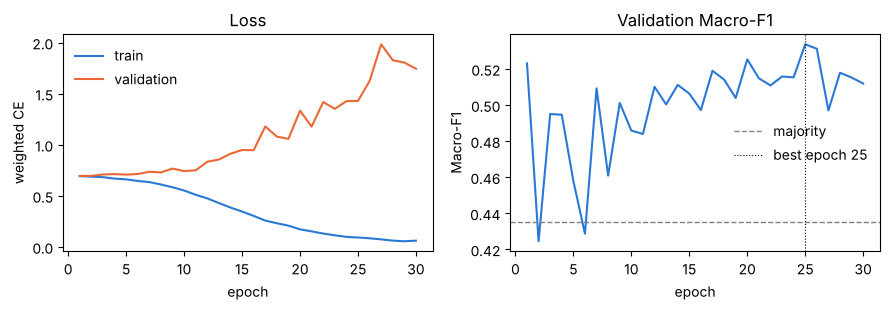

In [5]:
import matplotlib.pyplot as plt

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.2))
a.plot(log.epoch, log.train_loss, color="#2a78d6", label="train")
a.plot(log.epoch, log.val_loss, color="#eb6834", label="validation")
a.set_xlabel("epoch"); a.set_ylabel("weighted CE"); a.set_title("Loss"); a.legend(frameon=False)
b.plot(log.epoch, log.val_macro_f1, color="#2a78d6")
b.axhline(majority_baseline(y_val.numpy())["macro_f1"], color="gray", ls="--", lw=1, label="majority")
b.axvline(best["epoch"], color="black", lw=0.8, ls=":", label=f"best epoch {best['epoch']}")
b.set_xlabel("epoch"); b.set_ylabel("Macro-F1"); b.set_title("Validation Macro-F1"); b.legend(frameon=False)
fig.tight_layout()
print("confusion matrix [rows true 0/1, cols pred 0/1]:", get_confusion_matrix(y_val.numpy(), best["pred"].numpy()).tolist())

Validation loss rises after the first epochs while Macro-F1 keeps fluctuating and peaks late: the
head fits the training set almost perfectly (train ROC-AUC ≈ 1) and becomes over-confident on
validation. The epoch is chosen by Macro-F1 (README 5.1), not by loss. Whether less overfitting
would let fusion gain was tested with smaller and more regularized heads: not supported at the
sweep's resolution, about 0.02–0.03 Macro-F1 ([overfitting diagnostic](../Team_Review/multimodal/overfitting/README.md)).
/ 验证损失上升、Macro-F1 波动并在后期达到最高：分类头几乎完美拟合训练集（训练 ROC-AUC ≈ 1），并对验证集过度自信；按 Macro-F1 选 epoch。"减少过拟合能否让融合获益"已用更小、正则更强的分类头检验：在扫描的分辨率（约 0.02–0.03 Macro-F1）内不支持（见过拟合诊断）。

## 2. Which modality carries the signal? / 哪个模态有信号

In [6]:
rows = {"fusion [CLS] + image": best}
for name, path in (("text only", "configs/train/multimodal_text_only.yaml"),
                   ("image only", "configs/train/multimodal_image_only.yaml")):
    rows[name] = train(path)[3]
pd.DataFrame({k: {m: round(v[m], 4) for m in ("macro_f1", "accuracy", "f1_0", "f1_1")} | {"best epoch": v["epoch"]}
              for k, v in rows.items()}).T

,macro_f1,accuracy,f1_0,f1_1,best epoch
fusion [CLS] + image,0.5336,0.6567,0.2941,0.7732,25.0
text only,0.4903,0.6123,0.2409,0.7397,9.0
image only,0.5568,0.7253,0.2836,0.8301,29.0


In [7]:
# inference-time diagnostic: shuffle one modality across the validation set
g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(val_ids), generator=g)
head.eval()
with torch.no_grad():
    for name, feats in (("clean", f_val), ("text shuffled", {**f_val, "text": f_val["text"][perm]}),
                        ("image shuffled", {**f_val, "image": f_val["image"][perm]})):
        pred = (head(**feats).softmax(-1)[:, 1] >= cfg["threshold"]).long()
        print(f"{name:>15}: Macro-F1 {compute_metrics(y_val.numpy(), pred.numpy())['macro_f1']:.4f}")
# one permutation, seed 42 head; the report averages 20 permutations x 3 seeds

          clean: Macro-F1 0.5336
  text shuffled: Macro-F1 0.5016
 image shuffled: Macro-F1 0.5074


Seed 42 only; the 3-seed results and the statistical tests are in the
[results report](../Team_Review/multimodal/RESULTS_REPORT.md). / 只是 seed 42；三个 seed 的结果和统计检验见结果报告。

## 3. Shipped checkpoint → serving predictor / 已保存分类头 → 服务端预测器

In [8]:
import transformers
transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
from src.serving.predictor import MultimodalPredictor
from src.data.dataset import load_split

ckpt = "checkpoints/multimodal/20261016_distilbert_clip_seed42/best.pt"
text_dir, clip_dir = os.environ.get("TEXT_MODEL_DIR"), os.environ.get("CLIP_MODEL_DIR")  # offline copies
if Path(ckpt).exists():
    predictor = MultimodalPredictor.from_checkpoint(ckpt, text_dir, clip_dir, "cpu")
    samples = load_split("validation", "data/samples/synthetic_memotion")   # synthetic, not the dataset
    display(pd.DataFrame(predictor.predict(samples.text_input.tolist(), samples.image_abspath.tolist()),
                         index=samples.sample_id))
else:
    print("checkpoint not found: unzip Multimodal_Assets_20261016.zip (docs/Multimodal_Assets.md)")

,probability_sarcastic,predicted_label,label
sample_id,,,
validation_000000,0.737085,1,sarcastic
validation_000001,0.763847,1,sarcastic
validation_000002,0.286787,0,not_sarcastic
validation_000003,0.453961,0,not_sarcastic


The same predictor backs the HTTP API (`bash scripts/serve.sh`, [docs/api_spec.md](../docs/api_spec.md)).
On dataset samples it reproduces the run's `probability_1` to 6.4e-7 on CPU caches
(`python -m src.evaluation.end_to_end`).